# Hafta 10 — GPT-2'yi (124M) sıfırdan yazmak

Dokuz haftadır kendi küçük modellerimizi yazdık. Hafta 8'deki GPT 10,8 milyon parametreydi ve harf harf çalışıyordu. Bu hafta OpenAI'ın 2019'da yayımladığı GPT-2'nin en küçük sürümünü yazıyoruz: **124 milyon parametre, 12 blok, 768 boyutlu embedding, 50.257 token'lık vocab.**

Mimaride yeni bir şey yok: aynı attention, aynı blok, aynı residual. Fark ölçekte.

**Akış:** Önce OpenAI'ın eğittiği ağırlıkları Hugging Face'ten çekip inceliyoruz. Sonra aynı modeli kendimiz yazıp bu ağırlıkları içine yüklüyoruz ve konuşturuyoruz. En son modeli rastgele başlatıp ilk eğitim adımlarını atıyoruz.

| Görev | Konu | Video |
|---|---|---|
| 1 | Hazır GPT-2'yi incelemek: ağırlıklar, parametre sayısı, wpe | 0:03:39 – 0:13:47 |
| 2 | GPT-2'yi kendimiz yazıp ağırlıkları yüklemek | 0:13:47 – 0:31:00 |
| 3 | Sampling ve top-k: İngilizce ve Türkçe | 0:31:00 – 0:45:50 |
| 4 | İlk loss ve tek batch'i ezberletmek | 0:45:50 – 1:02:00 |
| Ek (b) | Türkçe ve İngilizce cümlelerin loss'u | |

**Kaynaklar:** [Karpathy, "Let's reproduce GPT-2 (124M)"](https://www.youtube.com/watch?v=l8pRSuU81PU) · [build-nanogpt](https://github.com/karpathy/build-nanogpt) · [GPT-2 makalesi](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) · [Hugging Face GPT-2](https://huggingface.co/openai-community/gpt2)

In [1]:
# Colab'da yoksa: !pip install tiktoken transformers
import math, time
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

# attempt to autodetect the device
device = "cpu"
if torch.cuda.is_available():
    device = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps" # Mac
print(f"using device: {device}")

using device: cpu


# **1- Hazır GPT-2'yi incele. Hugging Face'ten GPT-2 (124M) ağırlıklarını yükle. Her ağırlığın adını ve boyutunu yazdır, toplam parametre sayısını hesapla. Pozisyon embedding'lerini (wpe) çiz: ne görüyorsun, kendi cümlelerinle yaz. (0:03:39 - 0:13:47)**

OpenAI GPT-2'yi 2019'da TensorFlow ile yayımladı. Hugging Face'in `transformers` kütüphanesi aynı ağırlıkları PyTorch'a çevirip `GPT2LMHeadModel` sınıfıyla veriyor. `"gpt2"` en küçük sürüm (124M). `"gpt2-medium"`, `"gpt2-large"`, `"gpt2-xl"` (1,5B) daha büyükleri.

Karpathy'nin yaptığı gibi ilk iş bu modelin `state_dict`'ine bakıyoruz. `state_dict` ağırlıkların adından tensor'a giden bir sözlük. Kendi modelimizi yazarken bu adları ve boyutları birebir taklit edeceğiz ki ağırlıkları kopyalayabilelim.

In [2]:
from transformers import GPT2LMHeadModel
model_hf = GPT2LMHeadModel.from_pretrained("gpt2") # 124M
sd_hf = model_hf.state_dict() # ağırlık adı -> tensor

for k, v in sd_hf.items():
    print(k, v.shape)

C:\Users\Latif\venvs\freya\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

### Ağırlıkları okumak

- **`wte` (50257, 768):** token embedding. Vocab'daki her token için 768 boyutlu bir vektör. Hafta 8'deki `token_embedding_table`'ın aynısı, sadece 92 satır yerine 50.257 satır.
- **`wpe` (1024, 768):** pozisyon embedding. block_size 1024, yani model en fazla 1024 token'lık bağlam görüyor. Hafta 8'de 256'ydı.
- **`h.0` … `h.11`:** 12 blok, hepsi aynı yapıda. Her blokta:
  - `ln_1` ve `ln_2`: iki LayerNorm (weight + bias, 768'er)
  - `attn.c_attn` (768, 2304): q, k, v üçü birden, 2304 = 3 × 768
  - `attn.c_proj` (768, 768): head'lerin çıktısını birleştiren projeksiyon
  - `mlp.c_fc` (768, 3072) ve `mlp.c_proj` (3072, 768): feedforward, ara katman 4 × 768
- **`ln_f`:** son LayerNorm. **`lm_head` (50257, 768):** 768 boyutlu vektörü 50.257 token'ın logits'ine çeviriyor.

Dikkat edilmesi gereken bir şey: `c_attn.weight` (768, 2304) yazıyor, yani **(girdi, çıktı)**. PyTorch'un `nn.Linear`'ı bunun tersini tutuyor. Görev 2'de bu yüzden transpoze edeceğiz.

In [3]:
# toplam parametre sayısı. parameters() paylaşılan bir tensoru yalnızca bir kere veriyor
n_params = sum(p.numel() for p in model_hf.parameters())
print(f"toplam parametre: {n_params:,}")

# parametreler nereye gidiyor
wte = sd_hf["transformer.wte.weight"].numel()
wpe = sd_hf["transformer.wpe.weight"].numel()
blok = sum(v.numel() for k, v in sd_hf.items() if k.startswith("transformer.h.0.") and not k.endswith(".attn.bias") and not k.endswith(".attn.masked_bias"))
ln_f = sd_hf["transformer.ln_f.weight"].numel() + sd_hf["transformer.ln_f.bias"].numel()
print(f"wte (token embedding):   {wte:>12,}")
print(f"wpe (pozisyon embedding):{wpe:>12,}")
print(f"bir blok:                {blok:>12,}   x12 = {12 * blok:,}")
print(f"ln_f:                    {ln_f:>12,}")
print(f"toplam:                  {wte + wpe + 12 * blok + ln_f:>12,}")

# lm_head.weight ayrı bir tensor mü, yoksa wte'nin kendisi mi?
print("lm_head ile wte aynı tensor mü:", sd_hf["lm_head.weight"].data_ptr() == sd_hf["transformer.wte.weight"].data_ptr())

toplam parametre: 124,439,808
wte (token embedding):     38,597,376
wpe (pozisyon embedding):     786,432
bir blok:                   7,087,872   x12 = 85,054,464
ln_f:                           1,536
toplam:                   124,439,808
lm_head ile wte aynı tensor mü: True


### 124 milyon parametre nereden geliyor

| Parça | Parametre | Pay |
|---|---|---|
| `wte` | 38.597.376 (50.257 × 768) | %31 |
| `wpe` | 786.432 (1.024 × 768) | %0,6 |
| 12 blok | 85.054.464 (12 × 7.087.872) | %68 |
| `ln_f` | 1.536 | |
| **Toplam** | **124.439.808** | |

Bir bloğun 7.087.872 parametresinin dağılımı: `c_attn` 1.771.776 (768 × 2304 + 2304), `attn.c_proj` 590.592, `c_fc` 2.362.368, `mlp.c_proj` 2.360.064, iki LayerNorm 3.072. Yani bloğun üçte ikisi MLP'de, attention'da değil.

**`lm_head` nerede?** Tabloda yok çünkü `lm_head.weight` ile `wte.weight` **aynı tensor** (`data_ptr` aynı, True). `state_dict`'te iki ayrı anahtar olarak görünüyor ama bellekte tek bir matris var. Bunun adı **weight tying**: girdideki token embedding'i ile çıktıdaki sınıflandırıcı aynı ağırlıkları paylaşıyor. `parameters()` bu tensoru bir kere saydığı için 124M çıkıyor. İki kere sayılsaydı 163M olurdu. Görev 2'de kendi modelimizde tam olarak bunu göreceğiz.

min: -4.54  max: 4.07  std: 0.123  0. konumun en büyük değeri: 4.54


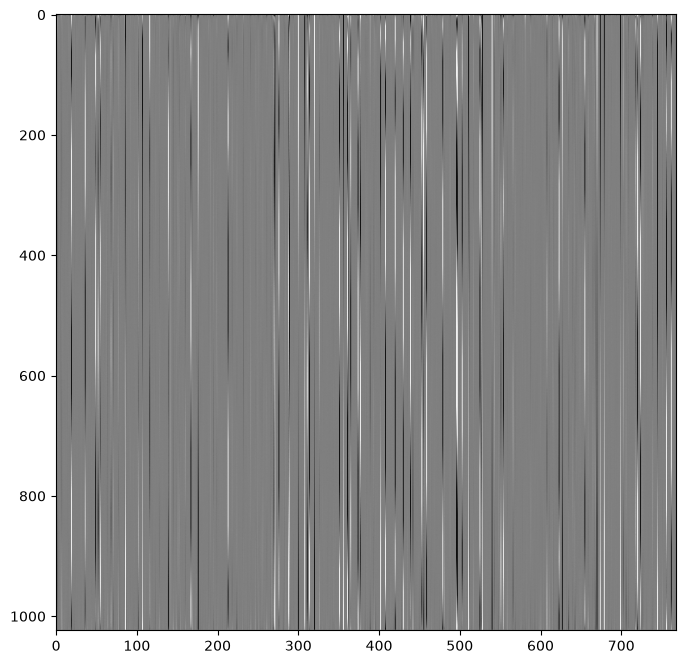

In [4]:
# her satır bir konum (0..1023), her sütun 768 boyuttan biri
w = sd_hf["transformer.wpe.weight"]
print(f"min: {w.min().item():.2f}  max: {w.max().item():.2f}  std: {w.std().item():.3f}  0. konumun en büyük değeri: {w[0].abs().max().item():.2f}")
# birkaç uç değer renk ölçeğini bastırıp her şeyi griye boyuyor, o yüzden ölçeği ±0.5'te kesiyoruz
plt.figure(figsize=(8, 8))
plt.imshow(w, cmap="gray", vmin=-0.5, vmax=0.5, aspect="auto")

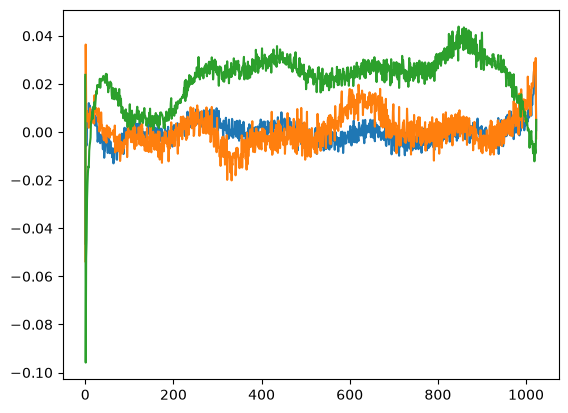

In [5]:
# üç tane boyutu konuma göre çizelim: o boyut konum ilerledikçe nasıl değişiyor
plt.plot(sd_hf["transformer.wpe.weight"][:, 150])
plt.plot(sd_hf["transformer.wpe.weight"][:, 200])
plt.plot(sd_hf["transformer.wpe.weight"][:, 250])

aralarında   1 konum olan çiftlerin ortalama benzerliği: 0.997
aralarında  10 konum olan çiftlerin ortalama benzerliği: 0.987
aralarında 100 konum olan çiftlerin ortalama benzerliği: 0.471
aralarında 500 konum olan çiftlerin ortalama benzerliği: 0.246


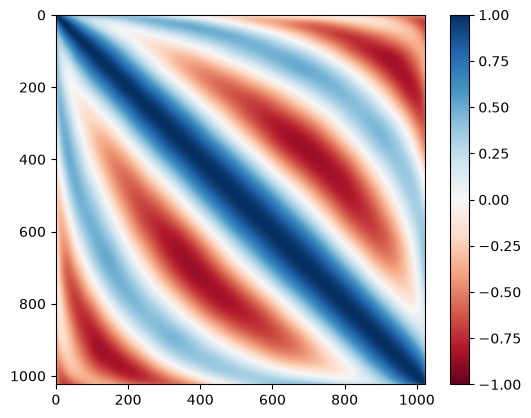

In [6]:
# konumlar birbirine ne kadar benziyor: her konum çiftinin kosinüs benzerliği
wpe_n = F.normalize(sd_hf["transformer.wpe.weight"], dim=1) # her satırı birim uzunluğa getiriyoruz
sim = wpe_n @ wpe_n.T # (1024, 1024)
plt.imshow(sim, cmap="RdBu", vmin=-1, vmax=1); plt.colorbar()
for d in [1, 10, 100, 500]:
    print(f"aralarında {d:3} konum olan çiftlerin ortalama benzerliği: {sim.diagonal(d).mean().item():.3f}")

### wpe'de ne görüyorum

- **Gri görsel:** Satırlar konum (0 yukarıda, 1023 aşağıda), sütunlar 768 boyut. En çok göze çarpan şey **dikey çizgiler**: bazı sütunlar bütün konumlarda koyu ya da açık kalıyor. Yani o boyutlar konuma göre pek değişmiyor, her konumda aşağı yukarı aynı değeri taşıyor. Konum bilgisi bu çizgilerin üstündeki yavaş değişimlerde. Değerlerin çoğu küçük (std 0,12), ama birkaç uç değer var: en büyüğü 4,5 ve 0. konumda, diğer konumlarda en fazla 1,6. İlk denemede `imshow` renk ölçeğini bu uç değerlere göre kurdu ve her şeyi düz griye boyadı, o yüzden ölçeği ±0,5'te kestik.
- **Tek tek boyutlar (150, 200, 250):** Konum ilerledikçe yavaşça inip çıkan, dalgalı eğriler. Yeşil (250) 0 ile 1000 arasında birkaç büyük dalga yapıyor, mavi ve turuncu daha küçük salınıyor. Üçü de 0. konumda ani bir sıçrama yapıyor: ilk konumun vektörü diğerlerinden çok farklı. Bu mantıklı, çünkü 0. konumdaki token'ın öncesinde hiçbir şey yok. "Attention Is All You Need"te pozisyon kodlaması elle yazılmış sinüs ve kosinüslerdi. GPT-2'de `wpe` öğrenilen bir parametre, kimse ona sinüs vermedi, ama eğitimin sonunda yine dalgaya benzeyen bir yapıya varmış.
- **Eğriler pürüzlü.** Karpathy bunu modelin tam eğitilmediğinin işareti olarak yorumluyor. Daha uzun eğitilmiş bir modelde bu eğrilerin daha düzgün olmasını beklerdik.
- **Kosinüs benzerliği:** Komşu konumlar 0,997, aralarında 10 konum olanlar 0,987, 100 konum olanlar 0,471, 500 konum olanlar 0,246. Isı haritasında köşegen boyunca koyu mavi bir bant var, ondan uzaklaştıkça dalgalar halinde açılıyor (kırmızı bölgeler zıt yönlü vektörler). Yakın konumların vektörleri neredeyse aynı, uzaklaştıkça benzerlik düşüyor. Bunu modele kimse söylemedi. Embedding tablosunun her satırı birbirinden bağımsız ve rastgele başlatılıyor, model konumları yalnızca 0'dan 1023'e kadar numara olarak görüyor. "3. konum 4. konuma yakın" bilgisini veriden kendisi öğrendi.

Karpathy'nin yaptığı gibi hazır modeli bir de Hugging Face'in kendi `pipeline`'ıyla konuşturalım. Görev 3'te aynısını kendi sampling döngümüzle yapacağız.

In [7]:
from transformers import pipeline, set_seed
generator = pipeline("text-generation", model="gpt2")
set_seed(42)
for out in generator("Hello, I'm a language model,", max_new_tokens=22, num_return_sequences=5, do_sample=True, top_k=50):
    print(">", out["generated_text"])

> Hello, I'm a language model, I'm a language model. In my mind, I'm doing the same thing as you. All these different
> Hello, I'm a language model, and I'm trying to understand what you're saying. In English, I have two English words: "l
> Hello, I'm a language model, so I don't get much of a chance to interact with objects. But I did find that I can do
> Hello, I'm a language model, a language model, a language model."
> Hello, I'm a language model, not a toolkit.

In a nutshell, I need to give language models a set of properties that


# **2- GPT-2'yi kendin yaz ve ağırlıkları yükle. Hafta 8'deki GPT'nden yola çıkarak GPT-2 modülünü yaz. Hugging Face ağırlıklarını kendi modeline yükle. Aynı girdi için kendi modelinin logits'inin Hugging Face modelininkiyle aynı çıktığını göster. Hafta 8'deki GPT'nden farklarını madde madde yaz, örneğin aktivasyon fonksiyonu ve q, k, v'nin tek katmanda hesaplanması. Bazı ağırlıkları yüklerken neden transpoze etmen gerektiğini de yaz. (0:13:47 - 0:31:00)**

Modülleri Hugging Face'teki adlarla yazıyoruz: `transformer.wte`, `transformer.h.0.attn.c_attn` gibi. Böylece `state_dict`'teki anahtarlar iki modelde aynı çıkıyor ve ağırlıkları tek bir döngüyle kopyalayabiliyoruz.

Önce bloğun parçaları: attention, MLP, blok, bir de hiperparametreleri tutan `GPTConfig`.

In [8]:
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd) # hafta 8'de her head'in ayrı key, query, value'su vardı. burada hepsi tek Linear
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        # not really a 'bias', more of a mask, but following the OpenAI/HF naming though
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size)) # hafta 8'deki tril maskesinin aynısı, adı HF'ye uysun diye bias

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x) # (B, T, 3C)
        q, k, v = qkv.split(self.n_embd, dim=2) # üç parçaya bölüyoruz, her biri (B, T, C)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs) head'ler batch boyutu gibi davranıyor, hepsi paralel hesaplanıyor
        # attention (materializes the large (T,T) matrix for all the queries and keys)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1))) # hafta 7'deki 1/sqrt(head_size) ölçeği
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side. hafta 8'deki torch.cat'in karşılığı
        # output projection
        y = self.c_proj(y)
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh') # hafta 8'de ReLU vardı. GPT-2 GELU'nun tanh yaklaşımını kullanıyor
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x)) # attention: token'lar birbiriyle iletişim kuruyor (reduce)
        x = x + self.mlp(self.ln_2(x))  # MLP: her token kendi başına düşünüyor (map)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension

Şimdi modelin kendisi. `from_pretrained` Hugging Face'ten ağırlıkları çekip bizim modelimize kopyalıyor.

In [9]:
class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd), # token embedding
            wpe = nn.Embedding(config.block_size, config.n_embd), # pozisyon embedding
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # 12 blok. HF'de adları h.0, h.1, ...
            ln_f = nn.LayerNorm(config.n_embd), # final layer norm
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False) # 768 -> 50257, bias yok

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb # (T, n_embd) batch boyunca yayılıyor (broadcast)
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1)) # (B*T, vocab_size) ve (B*T,). hafta 8'deki view'ın aynısı
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t()) # .t() ile transpoze edip kopyalıyoruz
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

In [10]:
model = GPT.from_pretrained("gpt2")
print("didn't crash yay!")
print(f"bizim modelin parametre sayısı: {sum(p.numel() for p in model.parameters()):,}")

loading weights from pretrained gpt: gpt2


didn't crash yay!
bizim modelin parametre sayısı: 163,037,184


Yükleme hatasız geçti, yani `assert`'lerin hepsi tuttu: her anahtarın adı ve boyutu (transpoze edilenlerde ters boyutu) iki modelde eşleşti.

Ama bizim modelin parametre sayısı **163.037.184**, HF'ninki 124.439.808. Fark 38.597.376, yani tam olarak `wte`'nin boyutu (50.257 × 768). HF modelinde `lm_head` ile `wte` aynı tensor, bizde iki ayrı tensor. Ağırlıkları yüklerken ikisine de aynı değerleri kopyaladık, o yüzden çıktı yine aynı olacak, ama bellekte aynı matrisin iki kopyası duruyor. Weight tying videonun 1:02:00'den sonraki kısmında ekleniyor ve modeli %24 küçültüyor (163M → 124M).

In [11]:
# neden transpoze: aynı katman iki modelde ters boyutta tutuluyor
print("HF  c_attn.weight:", tuple(sd_hf["transformer.h.0.attn.c_attn.weight"].shape), type(model_hf.transformer.h[0].attn.c_attn).__name__)
print("biz c_attn.weight:", tuple(model.transformer.h[0].attn.c_attn.weight.shape), type(model.transformer.h[0].attn.c_attn).__name__)
print("HF  mlp.c_fc.weight:", tuple(sd_hf["transformer.h.0.mlp.c_fc.weight"].shape))
print("biz mlp.c_fc.weight:", tuple(model.transformer.h[0].mlp.c_fc.weight.shape))

HF  c_attn.weight: (768, 2304) Conv1D
biz c_attn.weight: (2304, 768) Linear
HF  mlp.c_fc.weight: (768, 3072)
biz mlp.c_fc.weight: (3072, 768)


Şimdi asıl kontrol: aynı girdiyi iki modele verip logits'leri karşılaştırıyoruz. Ağırlıklar doğru yüklendiyse ve mimari birebir aynıysa iki çıktı (float hassasiyetinde) aynı olmalı.

In [12]:
import tiktoken # Colab'da yoksa: !pip install tiktoken
enc = tiktoken.get_encoding("gpt2") # GPT-2'nin tokenizer'ı, geçen haftaki BPE
x = torch.tensor(enc.encode("Hello, I'm a language model,"), dtype=torch.long).unsqueeze(0) # (1, T)

model.eval(); model_hf.eval()
with torch.no_grad():
    logits, _ = model(x)
    logits_hf = model_hf(x).logits
print("bizim logits:", tuple(logits.shape), " HF logits:", tuple(logits_hf.shape))
print("en büyük mutlak fark:", (logits - logits_hf).abs().max().item())
print("allclose (atol=1e-4):", torch.allclose(logits, logits_hf, atol=1e-4))
print("her konumda en olası token aynı mı:", torch.equal(logits.argmax(-1), logits_hf.argmax(-1)))

bizim logits: (1, 8, 50257)  HF logits: (1, 8, 50257)
en büyük mutlak fark: 7.62939453125e-05
allclose (atol=1e-4): True
her konumda en olası token aynı mı: True


In [13]:
# küçük bir deney: GELU'nun tanh yaklaşımı yerine tam GELU kullansaydık ne olurdu?
for blk in model.transformer.h:
    blk.mlp.gelu = nn.GELU() # tam GELU
with torch.no_grad():
    logits_tam, _ = model(x)
print("tam GELU ile en büyük fark:", (logits_tam - logits_hf).abs().max().item())
for blk in model.transformer.h:
    blk.mlp.gelu = nn.GELU(approximate='tanh') # geri alıyoruz

tam GELU ile en büyük fark: 0.07999420166015625


### Logits karşılaştırması

- Aynı 8 token'lık girdi (`"Hello, I'm a language model,"`) için iki model de (1, 8, 50257) logits verdi. **En büyük mutlak fark 7,6 × 10⁻⁵.** `torch.allclose(atol=1e-4)` True ve 8 konumun hepsinde en olası token aynı. Yani kendi yazdığımız model OpenAI'ın modeliyle aynı hesabı yapıyor.
- **Fark neden tam 0 değil?** İki model aynı çarpımı farklı yoldan yapıyor: HF'nin Conv1D'si `x @ W`, bizim Linear `x @ W.T`. Float32'de toplama sırası değişince son basamaklar değişiyor. 12 blok boyunca bu küçük farklar birikip 10⁻⁵ seviyesine çıkıyor.
- **GELU deneyi:** tanh yaklaşımı yerine tam GELU (`nn.GELU()`) koyunca fark **0,08**'e çıktı, yaklaşık 1000 kat. Aktivasyondaki küçük bir fark 12 blok boyunca büyüyor. Yani "logits aynı mı" testi gözle fark edilmeyecek mimari hataları bile yakalıyor. GPT-2'nin tanh yaklaşımını kullanmasının sebebi tarihsel: 2019'da TensorFlow'da tam GELU'yu hesaplayan `erf` yavaştı. Bugün gerek yok ama OpenAI'ın ağırlıklarını birebir kullanmak için biz de aynısını seçmek zorundayız.

### Hafta 8'deki GPT ile GPT-2'nin farkları

| | Hafta 8 GPT | GPT-2 (124M) |
|---|---|---|
| Tokenizer / vocab | karakter, 65 (Shakespeare) / 92 (Türkçe) | BPE, 50.257 |
| block_size | 256 | 1024 |
| n_embd / n_head / n_layer | 384 / 6 / 6 | 768 / 12 / 12 |
| Parametre | 10,8M | 124M |
| Aktivasyon | ReLU | GELU (tanh yaklaşımı) |
| q, k, v | her head'in ayrı key / query / value Linear'ı | tek `c_attn` Linear (768 → 2304) |
| q, k, v bias'ı | yok (`bias=False`) | var |
| `lm_head` bias'ı | var | yok |
| Dropout | 0.2 | yok |
| `wte` ve `lm_head` | ayrı | aynı tensor (bizim kodda henüz ayrı) |

1. **Aktivasyon: ReLU → GELU.** ReLU negatif girdide tam 0 veriyor ve gradient'i de 0. O nöron o örnekte hiçbir şey öğrenmiyor (hafta 4'teki ölü nöron sorunu). GELU negatif tarafta küçük, yumuşak bir eğri bırakıyor, gradient hiçbir yerde tamamen kesilmiyor.
2. **q, k, v tek katmanda hesaplanıyor.** Hafta 8'de 6 head vardı ve her head'in 3 ayrı Linear'ı vardı: 18 küçük matris çarpımı. Burada hepsi tek bir 768 × 2304'lük çarpım. Sonra `split` ile q, k, v'ye ayırıyoruz, `view(B, T, nh, hs).transpose(1, 2)` ile de head'lere bölüyoruz. Head boyutu batch boyutu gibi davranıyor ve PyTorch 12 head'i tek seferde paralel hesaplıyor. Matematiksel olarak hafta 8'dekiyle aynı, sadece GPU'da çok daha hızlı. Head çıktılarını birleştirmek de `torch.cat` yerine `transpose(1, 2).contiguous().view(B, T, C)` ile yapılıyor.
3. **Adlar HF ile aynı.** `nn.ModuleDict` içinde `wte`, `wpe`, `h`, `ln_f`, blokta `c_attn`, `c_fc`, `c_proj`. Bu adları seçmemizin tek sebebi ağırlıkları tek bir döngüyle kopyalayabilmek. Maske buffer'ının adının `bias` olması da bu yüzden.
4. **LayerNorm'un yeri.** Hafta 8'deki gibi pre-norm: LayerNorm attention'dan ve MLP'den **önce**, en sonda da `ln_f`. Hafta 8 ile aynı ama orijinal "Attention Is All You Need"ten farklı. Orada LayerNorm residual toplamadan **sonra** geliyordu. GPT-2 makalesi bunu "layer normalization was moved to the input of each sub-block … and an additional layer normalization was added after the final self-attention block" diye yazıyor. Pre-norm'da residual yolun üstünde hiçbir şey yok, gradient en üstten girdiye kadar engelsiz akıyor.
5. **Dropout yok.** 124M'lik model çok büyük bir veride az sayıda epoch eğitiliyor, ezberleme riski hafta 8'deki 1 MB'lık metindeki kadar büyük değil.

### Bazı ağırlıklar neden transpoze ediliyor

OpenAI GPT-2'yi TensorFlow'da yazdı. Attention ve MLP'deki dört katmanı (`attn.c_attn`, `attn.c_proj`, `mlp.c_fc`, `mlp.c_proj`) "Conv1D" diye bir modülle tanımladı. Adı konvolüsyon ama aslında düz bir Linear katman. Fark ağırlığın saklanma biçiminde:

- **Conv1D** ağırlığı **(girdi, çıktı)** diye tutuyor ve `x @ W` hesaplıyor: `c_attn` (768, 2304).
- **`nn.Linear`** ağırlığı **(çıktı, girdi)** diye tutuyor ve `x @ W.T` hesaplıyor: bizim `c_attn` (2304, 768).

Yani aynı matris ters yazılmış. Hugging Face orijinal ağırlıklara dokunmamak için Conv1D'yi korudu. Biz düz `nn.Linear` kullanmak istediğimiz için bu dört ağırlığı yüklerken `.t()` ile çeviriyoruz. Embedding'ler, LayerNorm'lar ve bias'lar iki tarafta da aynı biçimde, onlara dokunmuyoruz.

**Burada bir tuzak var:** `attn.c_proj` 768 × 768, yani kare bir matris. Transpoze etmeyi unutsaydık boyut kontrolü (`assert`) bunu yakalayamazdı, ağırlık sessizce yanlış yüklenirdi. Bu yüzden boyutların tutması yetmiyor, logits'i karşılaştırmak şart.

# **3- Modeli konuştur. Sampling döngüsünü yaz, top-k ile örnek üret. Önce İngilizce bir başlangıç cümlesi dene, sonra Türkçe bir cümle. GPT-2'nin Türkçe çıktısı neden kötü? Aynı Türkçe cümle GPT-2'nin tokenizer'ında kaç token tutuyor? Geçen haftaki sonuçlarınla bağla. (0:31:00 - 0:45:50)**

**Sampling döngüsü** hafta 3'ten beri yaptığımız şeyin aynısı: modelden son konumun logits'ini al, softmax ile olasılığa çevir, bir token çek, diziye ekle, tekrarla.

Tek yeni şey **top-k**. 50.257 token'ın çoğunun olasılığı çok küçük ama hepsini toplayınca küçük değil. Hepsinden çekersek arada bir saçma bir token geliyor ve metin raydan çıkıyor. Top-k yalnızca en olası k token'ı tutuyor, gerisini sıfırlıyor. Hugging Face'in `pipeline`'ı varsayılan olarak k = 50 kullanıyor, Karpathy de aynısını yapıyor.

In [14]:
def sample(model, prompt, num_return_sequences=5, max_length=30, seed=42):
    tokens = enc.encode(prompt)
    tokens = torch.tensor(tokens, dtype=torch.long) # (T,)
    tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1) # (5, T) aynı başlangıç 5 kere
    x = tokens.to(device)
    torch.manual_seed(seed)
    while x.size(1) < max_length:
        # forward the model to get the logits
        with torch.no_grad():
            logits, _ = model(x) # (B, T, vocab_size)
            # take the logits at the last position
            logits = logits[:, -1, :] # (B, vocab_size)
            # get the probabilities
            probs = F.softmax(logits, dim=-1)
            # do top-k sampling of 50 (huggingface pipeline default)
            # topk_probs here becomes (5, 50), topk_indices is (5, 50)
            topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
            # select a token from the top-k probabilities
            # note: multinomial does not demand the input to sum to 1
            ix = torch.multinomial(topk_probs, 1) # (B, 1) 50'nin içinden hangisi
            # gather the corresponding indices
            xcol = torch.gather(topk_indices, -1, ix) # (B, 1) o sıranın gerçek token id'si
            # append to the sequence
            x = torch.cat((x, xcol), dim=1)
    # print the generated text
    for i in range(num_return_sequences):
        tokens = x[i, :max_length].tolist()
        decoded = enc.decode(tokens)
        print(">", decoded)

model.to(device)
sample(model, "Hello, I'm a language model,")

> Hello, I'm a language model, not a science. I'm a language designer. I want to write, I want to think. I want
> Hello, I'm a language model, I use an English sentence structure, I like words over sentences.

"That's OK I'll look
> Hello, I'm a language model, not just another language." This isn't a "language model?" It's an idea. So far, what
> Hello, I'm a language model, not a programming model. I'm not a theoretical computer model - you read that right - because my ideas are
> Hello, I'm a language model, I teach myself.

I want to know more about how languages work and why they could be used.


Gördüğünüz gibi İngilizce çıktılar akıcı: dilbilgisi doğru, cümleler birbirine bağlanıyor ve konu "language model"den kopmuyor. Anlam olarak tutarlı değil ("I'm a language model, not a science"), ama 2019'dan 124M'lik bir model için iyi.

Seed aynı olmasına rağmen çıktılar Görev 1'deki `pipeline`'dan farklı. HF'nin `pipeline`'ı rastgele sayıları farklı sırada çekiyor, Karpathy videoda aynı farkı gösteriyor. Model aynı olduğu için kalite aynı. Aynı seed GPU'da (Colab) farklı rastgele sayılar üretiyor, o yüzden orada çalıştırınca örnek cümleler değişir.

In [15]:
sample(model, "Merhaba, ben bir dil modeliyim,")

> Merhaba, ben bir dil modeliyim, ben bev, ben brach,

e kos shayim mikdash
> Merhaba, ben bir dil modeliyim, mizuktir umegy, andy kalayim ayu. No
> Merhaba, ben bir dil modeliyim, de khatat. Nihat al-lik.

(1) To
> Merhaba, ben bir dil modeliyim, ben shaḭam, ben haddan. Ayaš, ben hadd
> Merhaba, ben bir dil modeliyim, aenim yitim, bistyim iniakhim gimradd


In [16]:
# biraz daha uzun bir Türkçe başlangıç
sample(model, "Türkiye'nin başkenti Ankara'dır. İstanbul ise", max_length=40)

> Türkiye'nin başkenti Ankara'dır. İstanbul iseştikır MİK. Lös nyüsün
> Türkiye'nin başkenti Ankara'dır. İstanbul isej, hulu bêzıd!

Istanbul - (Syd
> Türkiye'nin başkenti Ankara'dır. İstanbul iseşkoran aşştın şştılıtlar
> Türkiye'nin başkenti Ankara'dır. İstanbul iseşleriğlın.

Dalmarsyır, T
> Türkiye'nin başkenti Ankara'dır. İstanbul ise liraği.

(RNS) [email protected]

SECTION


Türkçe çıktılar ise anlamsız:

- "Merhaba, ben bir dil modeliyim,"den sonra `ben bev, ben brach`, `mizuktir umegy`, `ben shaḭam, ben haddan` gibi Türkçeye hiç benzemeyen, İbranice ya da Arapça isimlerin Latin harfli yazılışlarına benzeyen şeyler geliyor. Bazen de İngilizceye kaçıyor (`(1) To`, `No`).
- İkinci başlangıçta Türkçe harfler gelişigüzel diziliyor: `iseştikır MİK`, `aşştın şştılıtlar`. Bir örnekte de `[email protected]` ve `SECTION` var. Bunlar eğitim verisindeki web sayfalarından kalma kalıntılar. Model Türkçe bağlamda ne yapacağını bilmeyince gördüğü en sık metin parçalarına kayıyor.

**Neden kötü:**

1. **Eğitim verisi.** GPT-2 WebText'te eğitildi: Reddit'te en az 3 karma almış linklerin sayfaları, yaklaşık 40 GB metin. Makale (Bölüm 3.7) İngilizce olmayan sayfaların **bilerek çıkarıldığını** yazıyor: "we deliberately removed non-English webpages from WebText as a filtering step". Model Türkçeyi neredeyse hiç görmedi.
2. **Tokenizer.** BPE birleştirmeleri de aynı İngilizce veride öğrenildi. Türkçe harfler ve ekler için neredeyse hiç birleştirme yok (aşağıda).
3. **Bağlam.** Türkçe metin çok daha fazla token'a bölündüğü için aynı 1024 token'lık bağlama çok daha az Türkçe sığıyor.

In [17]:
# aynı cümle kaç token tutuyor
enc4 = tiktoken.get_encoding("cl100k_base") # GPT-4'ün tokenizer'ı, geçen hafta kullandık

for ad, s in [("İngilizce", "Hello, I'm a language model,"), ("Türkçe", "Merhaba, ben bir dil modeliyim,")]:
    ids = enc.encode(s)
    print(f"{ad:10} karakter: {len(s):2}  GPT-2 token: {len(ids):2}  GPT-4 token: {len(enc4.encode(s)):2}")
    print("           ", [enc.decode_single_token_bytes(i).decode("utf-8", errors="replace") for i in ids])

İngilizce  karakter: 28  GPT-2 token:  8  GPT-4 token:  8
            ['Hello', ',', ' I', "'m", ' a', ' language', ' model', ',']
Türkçe     karakter: 31  GPT-2 token: 11  GPT-4 token: 11
            ['Mer', 'hab', 'a', ',', ' ben', ' bir', ' dil', ' model', 'iy', 'im', ',']


In [18]:
# geçen haftaki paragraflar: aynı içerik, iki dil, iki tokenizer
tr_par = ("Sabah erkenden kalktım ve pencereyi açtım. Dışarıda hafif bir yağmur yağıyordu, sokaklar henüz sessizdi. "
          "Kahvaltıdan sonra kitaplarımı alıp kütüphaneye gittim. Akşama kadar orada çalıştım, sonra arkadaşlarımla buluşup eve döndük.")
en_par = ("I got up early in the morning and opened the window. A light rain was falling outside, and the streets were still quiet. "
          "After breakfast, I took my books and went to the library. I studied there until evening, then met my friends and we went home.")

for ad, e in [("GPT-2 (gpt2)", enc), ("GPT-4 (cl100k_base)", enc4)]:
    n_tr, n_en = len(e.encode(tr_par)), len(e.encode(en_par))
    print(f"{ad:20} Türkçe: {n_tr:3} token  İngilizce: {n_en:3} token  oran: {n_tr / n_en:.2f}   Türkçe byte/token: {len(tr_par.encode('utf-8')) / n_tr:.2f}")

# kelimeler hangi parçalara bölünüyor
for k in [" kütüphaneye", " arkadaşlarımla", " yağıyordu", " library", " friends"]:
    print(f"{k:16} GPT-2: {[enc.decode_single_token_bytes(t).decode('utf-8', errors='replace') for t in enc.encode(k)]}")

GPT-2 (gpt2)         Türkçe: 119 token  İngilizce:  54 token  oran: 2.20   Türkçe byte/token: 2.14
GPT-4 (cl100k_base)  Türkçe:  91 token  İngilizce:  54 token  oran: 1.69   Türkçe byte/token: 2.80
 kütüphaneye     GPT-2: [' k', 'ü', 't', 'ü', 'ph', 'ane', 'ye']
 arkadaşlarımla  GPT-2: [' ar', 'k', 'ada', 'ş', 'lar', 'ı', 'ml', 'a']
 yağıyordu       GPT-2: [' ya', 'ğ', 'ı', 'y', 'ord', 'u']
 library         GPT-2: [' library']
 friends         GPT-2: [' friends']


### Aynı cümle kaç token

- `"Hello, I'm a language model,"` 28 karakter, **8 token**. Her kelime tek token: `' language'`, `' model'`.
- `"Merhaba, ben bir dil modeliyim,"` 31 karakter, **11 token**: `Mer` · `hab` · `a` ve `model` · `iy` · `im`. "Merhaba" bile üçe bölünüyor. Kısa kelimeler (`ben`, `bir`, `dil`) tek token, çünkü bu harf dizileri İngilizce metinde de geçiyor.
- Bu kısa cümlede GPT-4'ün tokenizer'ı da 11 token çıkardı. Fark uzun metinde görünüyor:

| | Türkçe | İngilizce | Türkçe / İngilizce | Türkçe byte / token |
|---|---|---|---|---|
| GPT-2 (vocab 50.257) | 119 | 54 | **2,20** | 2,14 |
| GPT-4 cl100k (vocab ~100 bin) | 91 | 54 | **1,69** | 2,80 |

**Geçen haftayla bağlantı:** Geçen hafta GPT-4'ün tokenizer'ında aynı paragrafın Türkçede 1,69 kat token tuttuğunu bulmuştuk. GPT-2'de bu oran **2,20**. İngilizce iki tokenizer'da da 54 token, yani İngilizce için GPT-2'nin vocab'ı zaten yetiyordu. GPT-4'ün fazladan 50 bin token'ının bir kısmı Türkçe gibi dillere gitmiş ve Türkçe paragraf 119 token'dan 91'e inmiş.

**Kelimeler nasıl bölünüyor:** GPT-2'de `ü`, `ş`, `ğ`, `ı` çoğu zaman **tek başına bir token**: ` kütüphaneye` → ` k` · `ü` · `t` · `ü` · `ph` · `ane` · `ye` (7 token), ` arkadaşlarımla` 8 token. ` library` ve ` friends` ise tek token. Boşluktan sonra gelen `ç` tek token bile değil: ` çok` → ` \xc3` · `\xa7` · `ok`. Yani ç harfi UTF-8'in iki byte'ına bölünüyor (ek görevdeki dökümde `�` olarak görünüyor). Geçen hafta kendi Türkçe BPE'mizde ilk birleştirmelerin `ı`, `ü`, `ş`, `ç`, `ğ` olduğunu görmüştük: UTF-8'in ikiye böldüğü Türkçe harfleri geri toplamak. GPT-2'nin İngilizce verisinde bu harfler o kadar az geçiyor ki ` ç`'nin iki byte'ı bile birleşmemiş.

Sonuç olarak model her Türkçe kelime için 3 ile 7 arası tahmin yapmak zorunda ve her tahmin ayrı bir hata fırsatı. Üstelik bu parçaların çoğunu eğitimde neredeyse hiç görmedi.

# **4- İlk eğitim adımları. Modeli rastgele başlat ve ilk loss'u ölç, ln(50257) ≈ 10.8 ile karşılaştır. Neden bu değere yakın çıkmalı, kendi cümlelerinle yaz. Sonra tek bir batch'i ezberlet: aynı batch'te birkaç yüz adım eğit, loss sıfıra yaklaşmalı. Bu test neden işe yarıyor? (0:45:50 - 1:02:00)**

Karpathy eğitim verisi olarak yine Tiny Shakespeare'i kullanıyor. Farkı, artık metni harf harf değil GPT-2'nin tokenizer'ıyla token'lara bölüyoruz. Bu görevde metnin yalnızca ilk 1.000 karakteri yetiyor.

In [19]:
import os, urllib.request
if not os.path.exists("input.txt"): # tiny shakespeare
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "input.txt")
with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()
data = text[:1000] # first 1,000 characters
tokens = enc.encode(data)
print(f"1000 karakter -> {len(tokens)} token")
print(tokens[:24])

1000 karakter -> 285 token
[5962, 22307, 25, 198, 8421, 356, 5120, 597, 2252, 11, 3285, 502, 2740, 13, 198, 198, 3237, 25, 198, 5248, 461, 11, 2740, 13]


In [20]:
B, T = 4, 32
buf = torch.tensor(tokens[:B*T + 1]) # bir fazla token alıyoruz çünkü son konumun da hedefi lazım
x = buf[:-1].view(B, T) # girdiler
y = buf[1:].view(B, T)  # hedefler: her konum için bir sonraki token
print(x)
print(y)

tensor([[ 5962, 22307,    25,   198,  8421,   356,  5120,   597,  2252,    11,
          3285,   502,  2740,    13,   198,   198,  3237,    25,   198,  5248,
           461,    11,  2740,    13,   198,   198,  5962, 22307,    25,   198,
          1639,   389],
        [  477, 12939,  2138,   284,  4656,   621,   284,  1145,   680,    30,
           198,   198,  3237,    25,   198,  4965,  5634,    13, 12939,    13,
           198,   198,  5962, 22307,    25,   198,  5962,    11,   345,   760,
           327,  1872],
        [  385,  1526, 28599,   318,  4039,  4472,   284,   262,   661,    13,
           198,   198,  3237,    25,   198,  1135,   760,   470,    11,   356,
           760,   470,    13,   198,   198,  5962, 22307,    25,   198,  5756,
           514,  1494],
        [  683,    11,   290,   356,  1183,   423, 11676,   379,   674,   898,
          2756,    13,   198,  3792,   470,   257, 15593,    30,   198,   198,
          3237,    25,   198,  2949,   517,  3375,   319,  

İlk 1.000 karakter **285 token**'a indi, token başına yaklaşık 3,5 karakter. Harf seviyesinde 1.000 token olurdu. İlk token'lar: `5962` = `"First"`, `22307` = `" Citizen"`, `25` = `":"`, `198` = `"\n"`.

`buf` 4 × 32 + 1 = 129 token. `x` bunun ilk 128'i, `y` son 128'i. Yani `y`'nin her satırı `x`'in aynı satırının bir sağa kaymış hali: `x[0]` `5962, 22307, 25, …` ile başlıyor, `y[0]` `22307, 25, 198, …` ile. Her konumun hedefi bir sonraki token. Hafta 8'deki `get_batch` ile aynı mantık, sadece rastgele yerlerden değil metnin başından ardışık parçalar alıyoruz.

In [21]:
torch.manual_seed(1337)
model = GPT(GPTConfig()) # bu sefer HF ağırlıkları yok, rastgele başlatıyoruz
model.to(device)
x, y = x.to(device), y.to(device)

logits, loss = model(x, y)
print("logits:", tuple(logits.shape))
print(f"ilk loss:          {loss.item():.4f}")
print(f"ln(50257):         {math.log(50257):.4f}")

probs = F.softmax(logits, dim=-1)
print(f"logits std:        {logits.std().item():.3f}")
print(f"en büyük olasılık: {probs.max().item():.2e}   1/50257 = {1/50257:.2e}")

logits: (4, 32, 50257)
ilk loss:          10.8742
ln(50257):         10.8249
logits std:        0.577
en büyük olasılık: 2.84e-04   1/50257 = 1.99e-05


### İlk loss: 10,87 ve ln(50257) = 10,82

Rastgele başlatılmış bir model hiçbir şey bilmiyor. Bilmeyen bir modelden beklediğimiz, 50.257 token'ın hepsine aşağı yukarı eşit olasılık vermesi: her birine 1/50257. Cross-entropy doğru token'ın olasılığının eksi logaritması: −ln(1/50257) = ln(50257) = **10,82**.

Bizim ilk loss **10,87**, çok yakın. Sebebi logits'lerin küçük olması: std 0,58. Logits sıfıra yakın olunca softmax neredeyse düz bir dağılım veriyor. PyTorch'un varsayılan başlangıç değerleri (Linear'da ±1/√768) bunu sağlıyor. En büyük olasılık 2,8 × 10⁻⁴, düz dağılımın 2,0 × 10⁻⁵'inden 14 kat büyük. Yani dağılım tam düz değil ama loss'a etkisi küçük (0,05).

**Neden bu değere yakın çıkmalı:** Hafta 4'te aynı şeyi görmüştük. İlk loss ln(vocab)'dan çok **büyük** çıksaydı model bazı token'lara emin bir şekilde yüksek olasılık veriyor, doğru token'a ise neredeyse sıfır veriyor demekti. Bu durumda eğitimin ilk adımları bir şey öğrenmeye değil bu yanlış güveni kırmaya harcanır, loss eğrisi önce dik bir düşüş yapar (hokey sopası). İlk loss çok **küçük** çıksaydı kodda bir hata vardı, örneğin hedefler girdinin içine sızmıştı. ln(50257)'ye yakın olması iki şeyi gösteriyor: başlangıç değerleri makul ve loss doğru bağlanmış.

In [22]:
# tek batch'i ezberletiyoruz: her adımda aynı x, y
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4) # Adam + düzgün weight decay. lr Karpathy'nin ilk denemesi
losses = []
for i in range(200):
    t0 = time.time()
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    t1 = time.time()
    if i % 10 == 0 or i == 199:
        print(f"step {i:3}, loss: {loss.item():.4f}, dt: {(t1 - t0) * 1000:.0f}ms")

step   0, loss: 10.8742, dt: 2101ms


step  10, loss: 0.0929, dt: 1364ms


step  20, loss: 0.0145, dt: 1440ms


step  30, loss: 0.0059, dt: 1390ms


step  40, loss: 0.0036, dt: 1493ms


...

step 160, loss: 0.0010, dt: 1396ms


step 170, loss: 0.0009, dt: 1387ms


step 180, loss: 0.0009, dt: 1321ms


step 190, loss: 0.0009, dt: 1364ms


step 199, loss: 0.0008, dt: 1428ms


Text(0, 0.5, 'loss (log)')

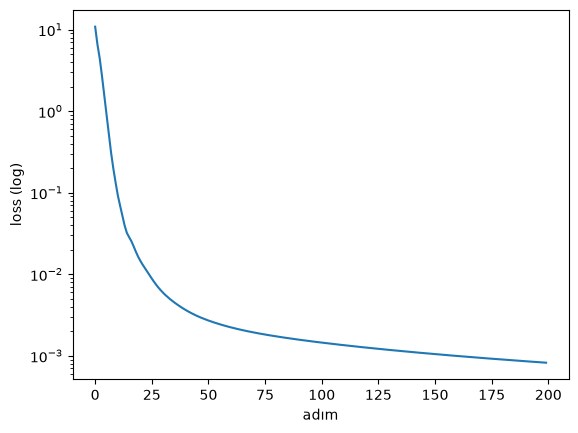

In [23]:
plt.plot(losses)
plt.yscale("log")
plt.xlabel("adım"); plt.ylabel("loss (log)")

In [24]:
# model batch'i gerçekten ezberledi mi? her konumda en olası token'ı hedefle karşılaştıralım
with torch.no_grad():
    logits, loss = model(x, y)
pred = logits.argmax(-1)
print(f"doğru tahmin oranı: {(pred == y).float().mean().item():.3f}")
print("hedef  :", repr(enc.decode(y[0].tolist())))
print("tahmin :", repr(enc.decode(pred[0].tolist())))

doğru tahmin oranı: 1.000
hedef  : ' Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all'
tahmin : ' Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all'


### Tek batch'i ezberletmek

- 10 adımda loss 10,87'den **0,093**'e, 200 adımda **0,0008**'e düştü. Log ölçekte eğri ilk 25 adımda dik, sonra yavaşça düşmeye devam ediyor.
- Son durumda 128 hedefin **hepsi** doğru tahmin ediliyor (oran 1,000). Tahmin edilen metin Shakespeare'in ilk satırlarıyla harfi harfine aynı.
- Adım süresi CPU'da 1,3 saniye civarında. İlk adım 4 saniye sürdü, çünkü ilk çağrıda bellek ayrılıyor. GPU'da çok daha hızlı.

**Bu test neden işe yarıyor:** 124 milyon parametreli bir modelin 128 token'ı ezberleyebilmesi gerekir, bu çok kolay bir görev. Ezberleyemiyorsa sorun veride ya da modelin kapasitesinde değil **kodda** demektir. Mesela `x` ile `y` yanlış kaydırılmış olabilir, loss yanlış boyutlarda hesaplanıyor olabilir, gradient bir katmana ulaşmıyor olabilir, optimizer yanlış parametreleri güncelliyor olabilir ya da lr çok küçük olabilir. Tek batch bu hataların hepsini birkaç dakikada ortaya çıkarıyor. Tam veriyle saatlerce eğitip sonra "loss neden düşmüyor" diye aramaktan çok daha ucuz.

Ama bu test genellemeyi ölçmüyor. Model bu 128 token'ı ezberledi, onun dışında hiçbir şey bilmiyor. Gelecek hafta bir data loader ile metnin tamamında eğiteceğiz.

# **Ek, erken bitirenler için, ikisinden biri. (a) Videonun devamına geç: küçük bir data loader yaz ve metnin tamamında eğit, weight tying'i ekle ve kaç parametre kazandırdığını hesapla, başlangıç değerlerini videodaki gibi ayarla. (1:02:00 - 1:22:18) (b) GPT-2'nin ağırlıklarını yükledikten sonra birkaç Türkçe cümlenin loss'unu ölç, aynı cümlelerin İngilizcesiyle karşılaştır. Fark neden bu kadar büyük? B SEÇENEĞİNİ SEÇTİM.**

Eğitilmiş GPT-2'yi tekrar yüklüyoruz ve her cümleyi hem token başına hem de karakter başına loss'la ölçüyoruz. Geçen haftaki toplantıda gördüğümüz gibi farklı tokenizer'ların ya da farklı dillerin loss'unu kıyaslamak için token başına loss adil değil: Türkçe cümle daha çok token'a bölünüyor ve her token daha az metin taşıyor. Karakter başına loss bu farkı ortadan kaldırıyor. Toplam loss'u (nats) karakter sayısına bölüyoruz.

In [25]:
model = GPT.from_pretrained("gpt2").to(device)
model.eval()

def olc(s):
    ids = torch.tensor(enc.encode(s), dtype=torch.long, device=device).unsqueeze(0)
    with torch.no_grad():
        _, loss = model(ids[:, :-1], ids[:, 1:]) # ilk token'ın tahmini yok, ondan sonraki her token tahmin ediliyor
    n = ids.size(1) - 1 # tahmin edilen token sayısı
    karakter = len(enc.decode(ids[0, 1:].tolist())) # tahmin edilen kısmın karakter sayısı
    return n, loss.item(), loss.item() * n / karakter # token sayısı, token başına loss, karakter başına loss

ciftler = [
    ("The weather is very nice today, let's go for a walk in the park.", "Bugün hava çok güzel, parkta yürüyüşe çıkalım."),
    ("I got up early in the morning and opened the window.", "Sabah erkenden kalktım ve pencereyi açtım."),
    ("After breakfast, I took my books and went to the library.", "Kahvaltıdan sonra kitaplarımı alıp kütüphaneye gittim."),
    ("The capital of Turkey is Ankara, and its largest city is Istanbul.", "Türkiye'nin başkenti Ankara, en büyük şehri ise İstanbul'dur."),
    (en_par, tr_par), # geçen haftaki paragraf
]

print(f"{'':4} {'token':>12} {'loss/token':>14} {'loss/karakter':>16}")
print(f"{'':4} {'en':>6}{'tr':>6} {'en':>7}{'tr':>7} {'en':>8}{'tr':>8}")
for i, (en, tr) in enumerate(ciftler):
    ne, le, ce = olc(en)
    nt, lt, ct = olc(tr)
    print(f"{i+1:<4} {ne:>6}{nt:>6} {le:>7.2f}{lt:>7.2f} {ce:>8.3f}{ct:>8.3f}")

loading weights from pretrained gpt: gpt2


            token     loss/token    loss/karakter
         en    tr      en     tr       en      tr


1        16    28    2.59   5.10    0.679   3.319


2        11    21    2.84   5.49    0.613   2.956


3        12    28    3.04   5.82    0.702   3.074


4        13    30    2.67   4.87    0.551   2.436


5        53   118    3.00   5.14    0.647   2.682


In [26]:
# Türkçe cümlede hangi token'lar pahalı: her token'ın kendi loss'u
ids = enc.encode("Bugün hava çok güzel, parkta yürüyüşe çıkalım.")
t = torch.tensor(ids, device=device).unsqueeze(0)
with torch.no_grad():
    logits, _ = model(t)
lp = F.log_softmax(logits[0, :-1], dim=-1) # (T-1, vocab_size)
for j in range(1, len(ids)):
    parca = enc.decode_single_token_bytes(ids[j]).decode("utf-8", errors="replace")
    print(f"{parca!r:12} loss: {-lp[j-1, ids[j]].item():5.2f}")

'ü'          loss: 10.58


'n'          loss:  3.92
' ha'        loss:  8.84
'va'         loss:  9.39
' �'         loss:  4.70
'�'          loss:  4.63
'ok'         loss:  8.54
' g'         loss:  5.84
'ü'          loss:  2.94
'zel'        loss:  6.65
','          loss:  3.36
' park'      loss: 11.92
'ta'         loss:  6.86
' y'         loss:  7.10
'ür'         loss:  6.89
'ü'          loss:  1.03
'y'          loss:  5.73
'ü'          loss:  0.76
'ş'          loss:  5.09
'e'          loss:  3.52
' �'         loss:  3.03
'�'          loss:  0.46
'ı'          loss:  4.10
'k'          loss:  2.99
'al'         loss:  5.45
'ı'          loss:  1.15
'm'          loss:  4.24
'.'          loss:  3.03


### Türkçe ve İngilizce cümlelerin loss'u

| Cümle | Token (en / tr) | Loss / token (en / tr) | Loss / karakter (en / tr) |
|---|---|---|---|
| 1 — hava güzel | 16 / 28 | 2,59 / 5,10 | 0,68 / 3,32 |
| 2 — pencereyi açtım | 11 / 21 | 2,84 / 5,49 | 0,61 / 2,96 |
| 3 — kütüphane | 12 / 28 | 3,04 / 5,82 | 0,70 / 3,07 |
| 4 — Ankara, İstanbul | 13 / 30 | 2,67 / 4,87 | 0,55 / 2,44 |
| 5 — geçen haftaki paragraf | 53 / 118 | 3,00 / 5,14 | 0,65 / 2,68 |

(Token sayıları tahmin edilen token'lar, yani ilk token hariç.)

- **Token başına loss** Türkçede yaklaşık **2 kat** (5,1 ve 3,0). Model her Türkçe token'da daha kararsız.
- **Karakter başına loss** Türkçede **4–5 kat** (2,4–3,3 ve 0,55–0,70). İki etki çarpılıyor: Türkçe yaklaşık 2,2 kat daha fazla token'a bölünüyor **ve** her token yaklaşık 2 kat daha pahalı.
- Hafta 8'de Ömer Seyfettin metninde eğittiğimiz 10,8M'lik harf modelinin val loss'u **1,50** idi. Harf modelinde loss zaten karakter başına. Metinler farklı olduğu için kaba bir kıyas, ama GPT-2 (124M) Türkçede karakter başına 2,4–3,3 ile bizim 10 kat küçük harf modelimizden daha kötü.

**Türkçe cümlenin token token dökümünde** (yukarıdaki hücre):

- **Pahalı token'lar:** `Bug` · **`ü`** 10,58, yani ln(50257) seviyesinde, model rastgele tahmin ediyor. `' ha'` · `'va'` 8,8 ve 9,4: "hava" gibi çok sık bir kelime bile iki pahalı parça. `' park'` 11,92: İngilizcede bildiği bir kelime ama anlamsız bir bağlamın ortasında hiç beklemiyor.
- **Ucuz token'lar:** Kelimenin ilk parçası gelince gerisi kolaylaşıyor. `yürüyüşe`'deki sonraki `ü`'ler 1,03 ve 0,76. ` ç`'nin ikinci byte'ı 0,46, çünkü UTF-8'de `\xc3`'ten sonra gelebilecek byte'lar sınırlı. Yani model UTF-8'in yapısını ve birkaç harf örüntüsünü öğrenmiş ama Türkçe kelimeleri bilmiyor.

**Fark neden bu kadar büyük:**

1. **Veri.** GPT-2 makalesinde yazdığı gibi İngilizce olmayan sayfalar WebText'ten bilerek çıkarıldı. Model Türkçeyi neredeyse hiç görmedi, Türkçe parçalar için öğrendiği olasılıklar zayıf.
2. **Tokenizer.** BPE de aynı İngilizce veride eğitildi. Türkçe 2,2 kat daha fazla token'a bölünüyor ve bu token'lar anlamı olmayan parçalar (`Mer` · `hab` · `a`). Her parça ayrı bir tahmin, her tahmin ayrı bir hata fırsatı.
3. **İki etki birbirini büyütüyor.** Tokenizer Türkçeyi küçük parçalara bölüyor, model bu parçaları az gördüğü için her birinde kötü, toplam loss katlanıyor. Geçen haftaki toplantıda gördüğümüz "loss'u karakter başına çevir" ölçüsü bu yüzden önemli: token başına bakınca fark 2 kat, karakter başına bakınca 4–5 kat.

## Özet

- GPT-2 (124M) mimari olarak hafta 8'deki GPT ile aynı. Farklar: GELU, q / k / v'nin tek `c_attn`'da hesaplanması, bias'lar, dropout'un olmaması, ölçek (768 / 12 / 12, block_size 1024, vocab 50.257) ve weight tying.
- 124.439.808 parametrenin 85M'i 12 blokta, 38,6M'i token embedding'inde. `lm_head`, `wte` ile aynı tensor. Bizim modelde ikisi henüz ayrı olduğu için 163M.
- `wpe` öğrenilen bir parametre ama dalga benzeri bir yapıya varmış: yakın konumların vektörleri birbirine benziyor.
- HF ağırlıklarını kendi modelimize yükledik, logits farkı 7,6 × 10⁻⁵. Conv1D ağırlığı (girdi, çıktı), Linear (çıktı, girdi) tuttuğu için dört ağırlık transpoze ediliyor.
- Top-k (k = 50) sampling ile İngilizce akıcı, Türkçe anlamsız. Aynı paragraf Türkçede GPT-2'de 2,20 kat, GPT-4'te 1,69 kat token tutuyor.
- Rastgele başlatılmış modelin ilk loss'u 10,87 ≈ ln(50257). Tek batch 200 adımda 0,0008'e indi ve 128 token'ın hepsi ezberlendi: kod doğru bağlanmış.
- Eğitilmiş GPT-2'de Türkçenin karakter başına loss'u İngilizcenin 4–5 katı.